# Actividad: Integración de SQL con Python

**Objetivo:**  
En esta actividad, pondrás en práctica todo lo aprendido en las guías sobre SQL y su integración con Python. Trabajarás con una base de datos que crearás localmente, la subirás a Google Drive y luego realizarás consultas y manipulaciones desde Google Colab usando Python. Este ejercicio simula un caso práctico de la vida real.

---

## Caso Práctico: Gestión de Inventarios en una Librería

Imagina que trabajas para una librería que quiere gestionar su inventario utilizando una base de datos. Deberás crear una base de datos que contenga la información de los libros disponibles, subirla a Google Drive y luego realizar varias consultas y operaciones desde Python en Google Colab.

## Puntos a Desarrollar

### Punto 1: Creación de la Base de Datos Localmente

1. **Crea una base de datos localmente utilizando SQLite y DB Browser for SQLite**. La base de datos debe llamarse `libreria.db`.
2. **Crea una tabla llamada `libros`** con las siguientes columnas:
   - `ID`: Entero, clave primaria, autoincremental.
   - `Titulo`: Texto.
   - `Autor`: Texto.
   - `Genero`: Texto.
   - `Precio`: Real.
   - `Stock`: Entero (cantidad de libros disponibles).

3. **Inserta las siguientes 20 filas con datos ficticios** que representen diferentes libros disponibles en la librería.

| ID  | Titulo                      | Autor              | Genero      | Precio | Stock |
|-----|-----------------------------|--------------------|-------------|--------|-------|
| 1   | El Quijote                  | Miguel de Cervantes| Clásico     | 19.99  | 12    |
| 2   | Cien Años de Soledad        | Gabriel García Márquez | Ficción  | 25.50  | 10    |
| 3   | Don Juan Tenorio            | José Zorrilla      | Clásico     | 15.00  | 8     |
| 4   | La Sombra del Viento        | Carlos Ruiz Zafón  | Ficción     | 22.95  | 7     |
| 5   | El Principito               | Antoine de Saint-Exupéry | Infantil | 18.25 | 15    |
| 6   | Moby Dick                   | Herman Melville    | Aventura    | 20.00  | 6     |
| 7   | La Odisea                   | Homero             | Clásico     | 21.50  | 4     |
| 8   | Harry Potter y la Piedra Filosofal | J.K. Rowling | Fantasía   | 30.00  | 25    |
| 9   | El Hobbit                   | J.R.R. Tolkien     | Fantasía    | 27.80  | 18    |
| 10  | Orgullo y Prejuicio         | Jane Austen        | Clásico     | 17.99  | 9     |
| 11  | El Código Da Vinci          | Dan Brown          | Misterio    | 24.00  | 14    |
| 12  | Los Juegos del Hambre       | Suzanne Collins    | Ciencia Ficción | 26.50 | 13    |
| 13  | 1984                        | George Orwell      | Ciencia Ficción | 22.00 | 11    |
| 14  | La Chica del Tren           | Paula Hawkins      | Thriller    | 21.99  | 8     |
| 15  | Matar a un Ruiseñor         | Harper Lee         | Clásico     | 18.75  | 7     |
| 16  | El Nombre del Viento        | Patrick Rothfuss   | Fantasía    | 29.99  | 10    |
| 17  | Las Aventuras de Sherlock Holmes | Arthur Conan Doyle | Misterio | 19.99 | 5     |
| 18  | El Retrato de Dorian Gray   | Oscar Wilde        | Clásico     | 16.50  | 10    |
| 19  | Viaje al Centro de la Tierra | Julio Verne       | Aventura    | 23.00  | 9     |
| 20  | Fahrenheit 451              | Ray Bradbury       | Ciencia Ficción | 19.99 | 12    |

4. **Guarda la base de datos** en tu computadora con el nombre `libreria.db`.

#### Evidencias creación base de datos sqlite browser

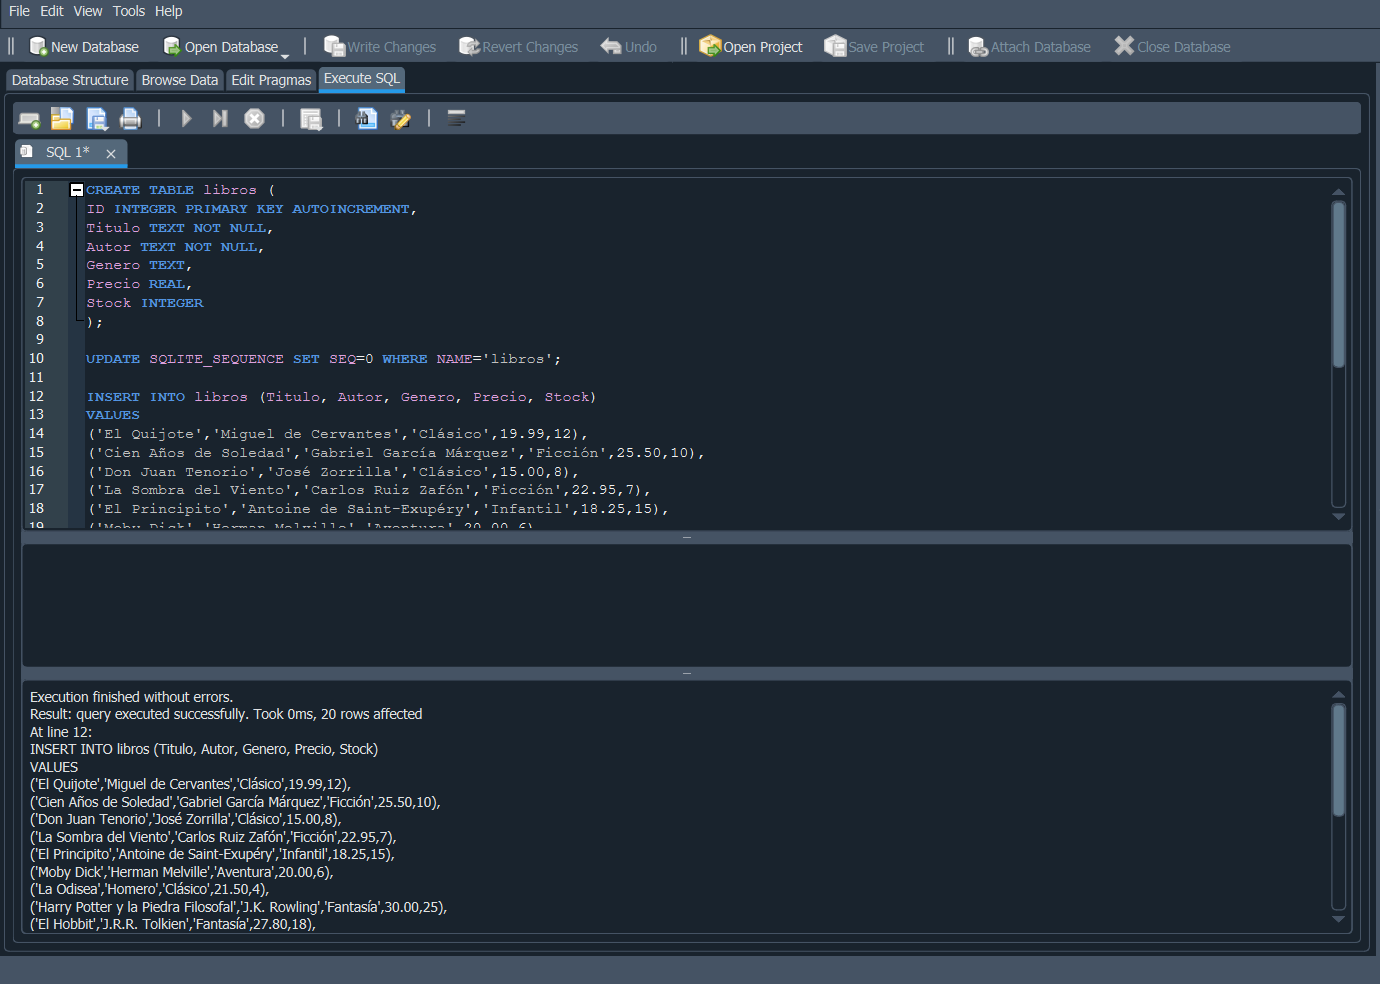

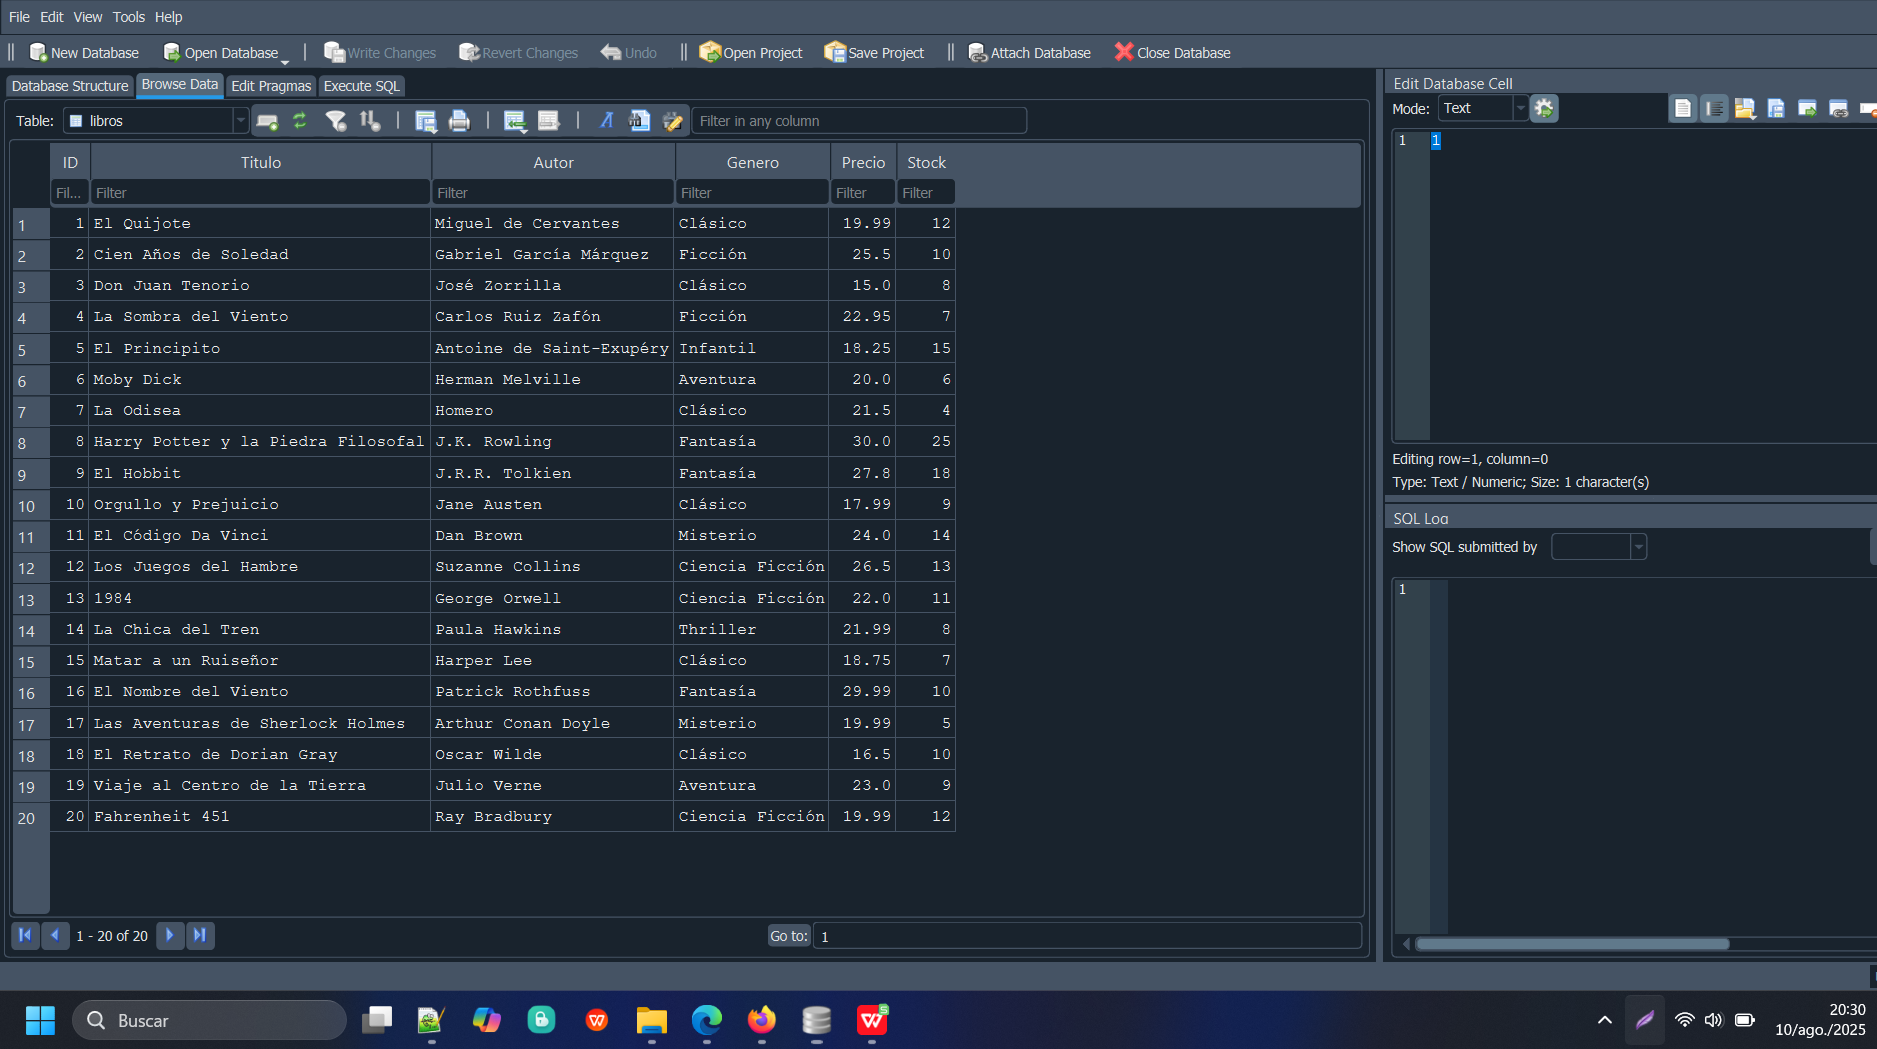

### Punto 2: Subir la Base de Datos a Google Drive

1. **Sube el archivo `libreria.db` a tu cuenta de Google Drive**.
2. **Obtén el ID del archivo** subido para usarlo en Google Colab.
3. **Asegúrate de configurar los permisos** de acceso del archivo para que puedas utilizarlo en Google Colab.

In [1]:
# ID del archivo libreria.db en mi Google Drive
id_archivo = '1njrY-kady7TBvttonWa_XsomTuwJugSA'

# Descargar el archivo libreria.db usando la librería wget
!wget --no-check-certificate 'https://drive.google.com/uc?export=download&id={id_archivo}' -O libreria.db


--2025-08-11 01:32:31--  https://drive.google.com/uc?export=download&id=1njrY-kady7TBvttonWa_XsomTuwJugSA
Resolving drive.google.com (drive.google.com)... 172.217.12.14, 2607:f8b0:4025:810::200e
Connecting to drive.google.com (drive.google.com)|172.217.12.14|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1njrY-kady7TBvttonWa_XsomTuwJugSA&export=download [following]
--2025-08-11 01:32:31--  https://drive.usercontent.google.com/download?id=1njrY-kady7TBvttonWa_XsomTuwJugSA&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.12.1, 2607:f8b0:4025:815::2001
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.12.1|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 12288 (12K) [application/octet-stream]
Saving to: ‘libreria.db’

libreria.db         100%[===================>]  12.00K  --.-KB/s    in 0s      

2025

### Punto 3: Conectar Google Colab con la Base de Datos en Google Drive

1. **Montar Google Drive en Google Colab**:

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


2. **Conectar con la base de datos `libreria.db`** utilizando Python y SQLite:

In [3]:
import sqlite3

# Ruta al archivo de la base de datos en Google Drive
#db_path = '/content/drive/MyDrive/Colab Notebooks/Curso Analítica de Datos/libreria.db'  # Completa la ruta con el nombre correcto
db_path = ('/content/libreria.db')

# Conectar a la base de datos SQLite
conexion = sqlite3.connect(db_path)
cursor = conexion.cursor()

# Mostrar las tablas en la base de datos
cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tablas = cursor.fetchall()

for tabla in tablas:
    print(tabla)

('libros',)
('sqlite_sequence',)


**Pista:** Verifica que la conexión ha sido exitosa imprimiendo los nombres de las tablas en la base de datos.

### Punto 4: Consultas SQL desde Python

1. **Realiza una consulta para mostrar todos los libros** que pertenecen al género "Ficción":

In [4]:
cursor.execute('''
SELECT *
FROM libros
WHERE Genero = 'Ficción';
''')
libros_ficcion = cursor.fetchall()

for libro in libros_ficcion:
    print(libro)

(2, 'Cien Años de Soledad', 'Gabriel García Márquez', 'Ficción', 25.5, 10)
(4, 'La Sombra del Viento', 'Carlos Ruiz Zafón', 'Ficción', 22.95, 7)


**Pista:** Completa los espacios en blanco seleccionando las columnas que necesitas y la tabla correcta.

2. **Calcula el precio promedio de los libros en la librería**:

In [5]:
cursor.execute('''
SELECT AVG(Precio)
FROM libros;
''')
precio_promedio = cursor.fetchone()[0]
print(f'El precio promedio de los libros es: {precio_promedio}')

El precio promedio de los libros es: 22.084500000000002


**Pista:** Usa una función agregada como `AVG` para calcular el precio promedio.

3. **Actualiza el stock de un libro específico** (por ejemplo, aumenta el stock de "El Quijote" en 5 unidades):

In [6]:
# Se usa la siguiente línea para validar el Stock antes de actualizarlo y después de hacerlo
res = cursor.execute('SELECT Titulo, Stock FROM libros WHERE Titulo = ?',('El Quijote',))
res = res.fetchall()
print("Stock del libro {} antes de actualizar: {}".format(res[0][0],res[0][1]))

cursor.execute('''
UPDATE libros
SET Stock = Stock + 5
WHERE Titulo = 'El Quijote';
''')
conexion.commit()

res = cursor.execute('SELECT Titulo, Stock FROM libros WHERE Titulo = ?',('El Quijote',))
res = res.fetchall()
print("Stock del libro {} después de actualizar: {}".format(res[0][0],res[0][1]))

Stock del libro El Quijote antes de actualizar: 12
Stock del libro El Quijote después de actualizar: 17


**Pista:** Asegúrate de usar la tabla y columnas correctas en tu `UPDATE`.

4. **Elimina todos los libros del género "Clásico" que tienen un stock de 0 unidades**:

In [7]:
# Se usa la siguiente línea para consultar los registros antes y después de la ejecución
res = cursor.execute('SELECT COUNT(*) FROM libros')
res = res.fetchone()
print("Numero de registros antes de eliminación: {}".format(res[0]))

cursor.execute('''
DELETE FROM libros
WHERE Genero = 'Clásico' AND Stock = 0;
''')
conexion.commit()

res = cursor.execute('SELECT COUNT(*) FROM libros')
res = res.fetchone()
print("Numero de registros después de eliminación: {}".format(res[0]))

#NOTA: Este caso no hay libros con Stock cero, por tanto no se eliminó ningún registro

Numero de registros antes de eliminación: 20
Numero de registros después de eliminación: 20


**Pista:** Recuerda usar la condición correcta para seleccionar los libros que necesitas eliminar.

### Punto 5: Análisis y Reflexión Final

1. **Realiza una consulta que muestre el total de libros por cada género**. Utiliza `GROUP BY` para agrupar los resultados:

In [8]:
cursor.execute('''
SELECT Genero,
COUNT(*)
FROM libros
GROUP BY Genero;
''')
total_libros_por_genero = cursor.fetchall()

for genero in total_libros_por_genero:
    print(f'Género: {genero[0]}, Total de libros: {genero[1]}')

Género: Aventura, Total de libros: 2
Género: Ciencia Ficción, Total de libros: 3
Género: Clásico, Total de libros: 6
Género: Fantasía, Total de libros: 3
Género: Ficción, Total de libros: 2
Género: Infantil, Total de libros: 1
Género: Misterio, Total de libros: 2
Género: Thriller, Total de libros: 1


**Pista:** Agrupa los resultados por el campo de `Genero` y cuenta los registros.

2. **Reflexiona sobre los resultados obtenidos** y responde:
   - ¿Qué conclusiones puedes sacar sobre la distribución de los géneros en la librería?
   - ¿Cómo podría optimizarse la gestión de inventarios utilizando SQL y Python en este contexto?

---

In [9]:
# Se puede usar Pandas para sacar conclusiones respecto a la última consulta
import pandas as pd

df = pd.DataFrame(total_libros_por_genero,columns=['Género','Cantidad_titulos_por_género'])

# Podemos generar una columna que nos muestre el porcentaje de la cantidad de libros por género

df['%_titulos_por_género'] = df['Cantidad_titulos_por_género']/(df['Cantidad_titulos_por_género'].sum())*100
df.sort_values('Cantidad_titulos_por_género',ascending=False)


,Género,Cantidad_titulos_por_género,%_titulos_por_género
2,Clásico,6,30.0
1,Ciencia Ficción,3,15.0
3,Fantasía,3,15.0
0,Aventura,2,10.0
4,Ficción,2,10.0
6,Misterio,2,10.0
5,Infantil,1,5.0
7,Thriller,1,5.0


  - ¿Qué conclusiones puedes sacar sobre la distribución de los géneros en la librería?
    - Se puede observar que el 30% de los títulos hace parte del género **Clásico**, lo cual lo hace un género importante y donde podrían estar concentradas la mayoría de ventas.
    - También, podemos ver que el 55% de los títulos se encuentra concentrado en los géneros **Clásico**, **Ciencia Ficción** y **Fantasía**, lo que podría indicar una tendencia a adquirir este género por parte de la librería basado en análisis de ventas anteriores
    - Para los otros géneros, los cuales tienen porcentajes de títulos menores al 10%, se puede pensar que son de baja circulación y tal vez con potencial para generar estrategias que ayuden a mejorar las ventas de estos géneros y aumentar la adquisición de títulos relativos a estos.

- ¿Cómo podría optimizarse la gestión de inventarios utilizando SQL y Python en este contexto?
  - Se podría aprovechar la integración de SQL para programar procesos en Python que permitan generar reportes relativos a ventas totales, ventas por género, stock actual de libros
  - También se podría usar Python para que realice los cálculos y envíe alertas cuando los inventarios de algún título o género estén bajos (definiendo un valor límite para la alerta)
  - Tambíen, se podrían analizar cotizaciones de libros, generando reportes de variación de precios de compra y venta y comparando con los valores cotizados
  - Toda esta información se puede hacer persistente generando nuevas tablas en base de datos o creando nuevos archivos en otros sistemas, que contengan los insights calculados y que puedan ser luego consultados para generar dashboards o reportes contables sobre la gestión de inventarios
  - Todo esto se podría integrar a pipelines automatizados que corran las diferentes tareas según una frecuencia deseada (diaria, mensual, anual, etc)